In [1]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
# Path to your .ttf
font_path = "/home/links/mf671/times.ttf"

# Add the font to Matplotlib's font manager
fm.fontManager.addfont(font_path)

# Get the name of the font inside the .ttf
font_name = fm.FontProperties(fname=font_path).get_name()

# Set as default
plt.rcParams['font.family'] = font_name
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
import numpy as np
from tqdm import tqdm
import cftime
from dask.diagnostics import ProgressBar

/home/links/mf671/miniconda3/envs/falwa_env/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
#ProgressBar().register()

# Path to data and experiments
base_path = '/home/links/mf671/DATA/isca_data'
experiments = [
    'exeter_project_mf_baseline_KS',
    'exeter_project_mf_aa_KS_30_72,90',
    'exeter_project_mf_baseline_st_KS',
    'exeter_project_mf_aa_st_KS_30_72,90'
]

# Load datasets
ds_clims = []

for i,experiment in enumerate(experiments):
    if i<2:
        ds = xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-51_wbeta.nc')
    if i>=2:
        ds = xr.open_dataset(f'{base_path}/{experiment}/tot/FC_1.5x1.5_2-51_wbeta.nc')
    ds_clims.append(ds)

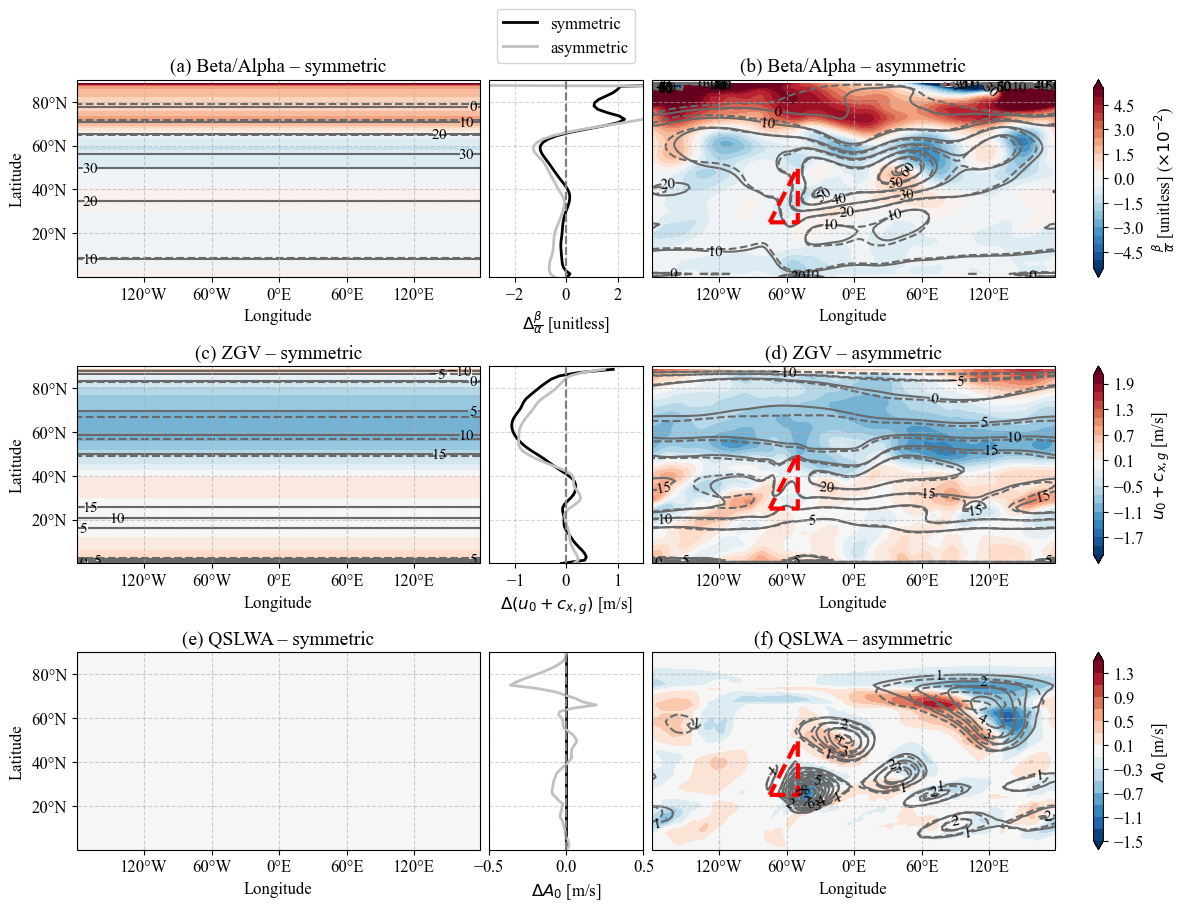

In [6]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
from matplotlib.ticker import ScalarFormatter

plt.rcParams['axes.formatter.use_mathtext'] = True
plt.rcParams['font.size'] = 12

formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0,0))

# --------------------------------------------------
# Helper
# --------------------------------------------------
def broadcast_zonal(field, ds_ref):
    zonal = field.mean('lon')
    return zonal.broadcast_like(ds_ref)

# --------------------------------------------------
# Figure layout (same as new Figure 5)
# --------------------------------------------------
fig = plt.figure(figsize=(17,10))

gs = gridspec.GridSpec(
    nrows=3,
    ncols=5,
    width_ratios=[6.0,0.25,1.2,0.01,6.0],
    hspace=0.45,
    wspace=-0.3
)

titles  = ['symmetric','asymmetric']
letters = ['(a)','(c)','(e)','(b)','(d)','(f)']
colors  = ['k','silver']

coords = [(-75.0,25.0),(-50.0,25.0),(-50.0,50.0)]
lons,lats = zip(*coords)
lons = np.array(lons)
lats = np.array(lats)

lons_closed = np.append(lons,lons[0])
lats_closed = np.append(lats,lats[0])

proj = ccrs.PlateCarree()

# --------------------------------------------------
# Loop symmetric / asymmetric
# --------------------------------------------------
for i in range(2):

    XSEC_COL = 2
    MAP_COL  = 0 if i==0 else 4

    ds_a = ds_clims[i*2]
    ds_b = ds_clims[i*2+1]

    # ==================================================
    # ROW 1 — BETA/ALPHA
    # ==================================================
    if i==0:
        ax_xsec_alpha = fig.add_subplot(gs[0,XSEC_COL])

    ax_map = fig.add_subplot(gs[0,MAP_COL],projection=proj,sharey=ax_xsec_alpha)

    field_a = ds_a['beta']/ds_a['alpha']
    field_b = ds_b['beta']/ds_b['alpha']

    if i==0:
        field_a = broadcast_zonal(field_a,ds_a)
        field_b = broadcast_zonal(field_b,ds_a)

    levels = np.arange(0,0.8,0.1)*100
    levels_diff = np.arange(-0.055,0.056,0.005)*100

    ax_map.set_title(f'{letters[i*3]} Beta/Alpha – {titles[i]}')

    c1 = ax_map.contour(ds_a.lon,ds_a.lat,field_a,
                        levels=levels,colors='dimgray',linewidths=1.5)

    ax_map.contour(ds_b.lon,ds_b.lat,field_b,
                   levels=levels,colors='dimgray',
                   linestyles='dashed',linewidths=1.5)

    ax_map.clabel(c1,inline=True,colors='black',fontsize=11)

    alpha_diff = field_b-field_a

    sh = ax_map.contourf(ds_a.lon,ds_a.lat,alpha_diff,
                         levels=levels_diff,
                         cmap='RdBu_r',extend='both')

    if i>0:
        cbar = fig.colorbar(sh,ax=ax_map)
        cbar.ax.yaxis.set_major_formatter(formatter)
        cbar.ax.yaxis.get_offset_text().set_visible(False)
        cbar.set_label(r'$\frac{\beta}{\alpha}$ [unitless] ($\times 10^{-2}$)')

    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120],crs=proj)
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    if i==0:
        ax_map.set_yticks([20,40,60,80])
        ax_map.set_yticklabels(['20°N','40°N','60°N','80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(),visible=False)

    if i>0:
        ax_map.plot(lons_closed,lats_closed,'--',lw=3,color='red',transform=proj)

    ax_map.gridlines(draw_labels=False,linestyle='--',alpha=0.6)

    xsec = alpha_diff.mean('lon').values

    ax_xsec_alpha.plot(xsec,ds_a.lat.values,color=colors[i],lw=2,label=titles[i])
    ax_xsec_alpha.axvline(0,color='gray',ls='--')
    ax_xsec_alpha.set_xlim([-3,3])
    #ax_xsec_alpha.ticklabel_format(style='scientific',axis='x',scilimits=(0,0))
    ax_xsec_alpha.set_xlabel(r'$\Delta\frac{\beta}{\alpha}$ [unitless]')
    ax_xsec_alpha.grid(True,ls='--',alpha=0.5)
    ax_xsec_alpha.tick_params(axis='y',length=0)

    plt.setp(ax_xsec_alpha.get_yticklabels(),visible=False)

    ax_xsec_alpha.legend(loc='upper right',bbox_to_anchor=(1.0,1.4))

    # ==================================================
    # ROW 2 — ZGV
    # ==================================================
    if i==0:
        ax_xsec_zgv = fig.add_subplot(gs[1,XSEC_COL])

    ax_map = fig.add_subplot(gs[1,MAP_COL],projection=proj,sharey=ax_xsec_zgv)

    field_a = ds_a['zgv']
    field_b = ds_b['zgv']

    if i==0:
        field_a = broadcast_zonal(field_a,ds_a)
        field_b = broadcast_zonal(field_b,ds_a)

    levels = np.arange(-10,30,5)
    levels_diff = np.arange(-2.1,2.2,0.2)

    ax_map.set_title(f'{letters[i*3+1]} ZGV – {titles[i]}')

    c1 = ax_map.contour(ds_a.lon,ds_a.lat,field_a,
                        levels=levels,colors='dimgray',linewidths=1.5)

    ax_map.contour(ds_b.lon,ds_b.lat,field_b,
                   levels=levels,colors='dimgray',
                   linestyles='dashed',linewidths=1.5)

    ax_map.clabel(c1,inline=True,colors='black',fontsize=11)

    zgv_diff = field_b-field_a

    sh = ax_map.contourf(ds_a.lon,ds_a.lat,zgv_diff,
                         levels=levels_diff,
                         cmap='RdBu_r',extend='both')

    if i>0:
        fig.colorbar(sh,ax=ax_map,label=r'$u_0 + c_{x,g}$ [m/s]')

    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120],crs=proj)
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    if i==0:
        ax_map.set_yticks([20,40,60,80])
        ax_map.set_yticklabels(['20°N','40°N','60°N','80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(),visible=False)

    if i>0:
        ax_map.plot(lons_closed,lats_closed,'--',lw=3,color='red',transform=proj)

    ax_map.gridlines(draw_labels=False,linestyle='--',alpha=0.6)

    xsec = zgv_diff.mean('lon').values

    ax_xsec_zgv.plot(xsec,ds_a.lat.values,color=colors[i],lw=2,label=titles[i])
    ax_xsec_zgv.axvline(0,color='gray',ls='--')
    ax_xsec_zgv.set_xlim([-1.5,1.5])
    ax_xsec_zgv.set_xlabel(r'$\Delta(u_0 + c_{x,g})$ [m/s]')
    ax_xsec_zgv.grid(True,ls='--',alpha=0.5)
    ax_xsec_zgv.tick_params(axis='y',length=0)

    plt.setp(ax_xsec_zgv.get_yticklabels(),visible=False)

    # ==================================================
    # ROW 3 — QSLWA
    # ==================================================
    if i==0:
        ax_xsec_qslwa = fig.add_subplot(gs[2,XSEC_COL])

    ax_map = fig.add_subplot(gs[2,MAP_COL],projection=proj,sharey=ax_xsec_qslwa)

    field_a = ds_a['qslwa']
    field_b = ds_b['qslwa']

    if i==0:
        field_a = xr.zeros_like(field_a)
        field_b = xr.zeros_like(field_b)

    levels = np.arange(1,10,1)
    levels_diff = np.arange(-1.5,1.6,0.2)

    ax_map.set_title(f'{letters[i*3+2]} QSLWA – {titles[i]}')

    c1 = ax_map.contour(ds_a.lon,ds_a.lat,field_a,
                        levels=levels,colors='dimgray',linewidths=1.5)

    ax_map.contour(ds_b.lon,ds_b.lat,field_b,
                   levels=levels,colors='dimgray',
                   linestyles='dashed',linewidths=1.5)

    ax_map.clabel(c1,inline=True,colors='black',fontsize=11)

    qslwa_diff = field_b-field_a

    sh = ax_map.contourf(ds_a.lon,ds_a.lat,qslwa_diff,
                         levels=levels_diff,
                         cmap='RdBu_r',extend='both')

    if i>0:
        fig.colorbar(sh,ax=ax_map,label=r'$A_0$ [m/s]')

    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120],crs=proj)
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    if i==0:
        ax_map.set_yticks([20,40,60,80])
        ax_map.set_yticklabels(['20°N','40°N','60°N','80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(),visible=False)

    if i>0:
        ax_map.plot(lons_closed,lats_closed,'--',lw=3,color='red',transform=proj)

    ax_map.gridlines(draw_labels=False,linestyle='--',alpha=0.6)

    xsec = qslwa_diff.mean('lon').values

    ax_xsec_qslwa.plot(xsec,ds_a.lat.values,color=colors[i],lw=2,label=titles[i])
    ax_xsec_qslwa.axvline(0,color='gray',ls='--')
    ax_xsec_qslwa.set_xlim([-0.5,0.5])
    ax_xsec_qslwa.set_xlabel(r'$\Delta A_0$ [m/s]')
    ax_xsec_qslwa.grid(True,ls='--',alpha=0.5)
    ax_xsec_qslwa.tick_params(axis='y',length=0)

    plt.setp(ax_xsec_qslwa.get_yticklabels(),visible=False)

# --------------------------------------------------
plt.savefig('PLOTS/Figure6_wxsec.png',dpi=300,bbox_inches='tight')
plt.show()

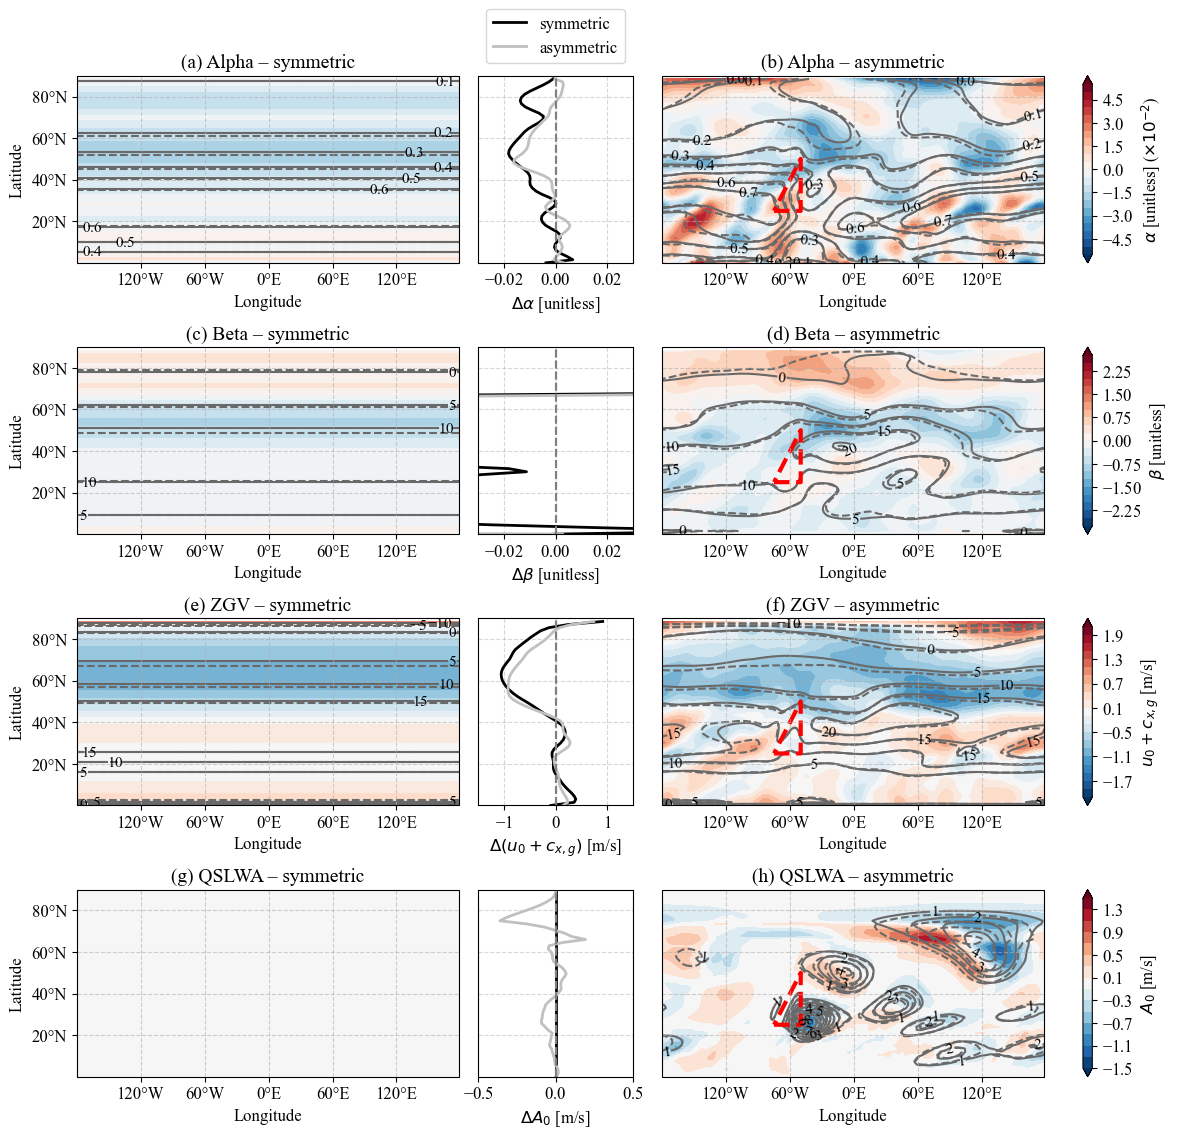

In [4]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
from matplotlib.ticker import ScalarFormatter

plt.rcParams['axes.formatter.use_mathtext'] = True
plt.rcParams['font.size'] = 12

formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0,0))

# --------------------------------------------------
# Helper
# --------------------------------------------------
def broadcast_zonal(field, ds_ref):
    zonal = field.mean('lon')
    return zonal.broadcast_like(ds_ref)

# --------------------------------------------------
# Figure layout
# --------------------------------------------------
fig = plt.figure(figsize=(17,13))

gs = gridspec.GridSpec(
    nrows=4,
    ncols=5,
    width_ratios=[6.0,0.25,1.2,0.01,6.0],
    hspace=0.45,
    wspace=-0.3
)

titles  = ['symmetric','asymmetric']
letters = ['(a)','(c)','(e)','(g)','(b)','(d)','(f)','(h)']
colors  = ['k','silver']

coords = [(-75.0,25.0),(-50.0,25.0),(-50.0,50.0)]
lons,lats = zip(*coords)
lons = np.array(lons)
lats = np.array(lats)

lons_closed = np.append(lons,lons[0])
lats_closed = np.append(lats,lats[0])

proj = ccrs.PlateCarree()

# --------------------------------------------------
# Loop symmetric / asymmetric
# --------------------------------------------------
for i in range(2):

    XSEC_COL = 2
    MAP_COL  = 0 if i==0 else 4

    ds_a = ds_clims[i*2]
    ds_b = ds_clims[i*2+1]

    # ==================================================
    # ROW 1 — ALPHA
    # ==================================================
    if i==0:
        ax_xsec_alpha = fig.add_subplot(gs[0,XSEC_COL])

    ax_map = fig.add_subplot(gs[0,MAP_COL],projection=proj,sharey=ax_xsec_alpha)

    field_a = ds_a['alpha']
    field_b = ds_b['alpha']

    if i==0:
        field_a = broadcast_zonal(field_a,ds_a)
        field_b = broadcast_zonal(field_b,ds_a)

    levels = np.arange(0,0.8,0.1)
    levels_diff = np.arange(-0.055,0.056,0.005)

    ax_map.set_title(f'{letters[i*4]} Alpha – {titles[i]}')

    c1 = ax_map.contour(ds_a.lon,ds_a.lat,field_a,
                        levels=levels,colors='dimgray',linewidths=1.5)

    ax_map.contour(ds_b.lon,ds_b.lat,field_b,
                   levels=levels,colors='dimgray',
                   linestyles='dashed',linewidths=1.5)

    ax_map.clabel(c1,inline=True,colors='black',fontsize=11)

    alpha_diff = field_b-field_a

    sh = ax_map.contourf(ds_a.lon,ds_a.lat,alpha_diff,
                         levels=levels_diff,
                         cmap='RdBu_r',extend='both')

    if i>0:
        cbar = fig.colorbar(sh,ax=ax_map)
        cbar.ax.yaxis.set_major_formatter(formatter)
        cbar.ax.yaxis.get_offset_text().set_visible(False)
        cbar.set_label(r'$\alpha$ [unitless] ($\times 10^{-2}$)')

    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120],crs=proj)
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    if i==0:
        ax_map.set_yticks([20,40,60,80])
        ax_map.set_yticklabels(['20°N','40°N','60°N','80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(),visible=False)

    if i>0:
        ax_map.plot(lons_closed,lats_closed,'--',lw=3,color='red',transform=proj)

    ax_map.gridlines(draw_labels=False,linestyle='--',alpha=0.6)

    xsec = alpha_diff.mean('lon').values

    ax_xsec_alpha.plot(xsec,ds_a.lat.values,color=colors[i],lw=2,label=titles[i])
    ax_xsec_alpha.axvline(0,color='gray',ls='--')
    ax_xsec_alpha.set_xlim([-0.03,0.03])
    ax_xsec_alpha.set_xlabel(r'$\Delta\alpha$ [unitless]')
    ax_xsec_alpha.grid(True,ls='--',alpha=0.5)
    ax_xsec_alpha.tick_params(axis='y',length=0)

    plt.setp(ax_xsec_alpha.get_yticklabels(),visible=False)

    ax_xsec_alpha.legend(loc='upper right',bbox_to_anchor=(1.0,1.4))

    # ==================================================
    # ROW 2 — BETA  (NEW)
    # ==================================================
    if i==0:
        ax_xsec_beta = fig.add_subplot(gs[1,XSEC_COL])

    ax_map = fig.add_subplot(gs[1,MAP_COL],projection=proj,sharey=ax_xsec_beta)

    field_a = ds_a['beta']
    field_b = ds_b['beta']

    if i==0:
        field_a = broadcast_zonal(field_a,ds_a)
        field_b = broadcast_zonal(field_b,ds_a)

    # TODO: adjust these ranges to the values of beta
    levels = np.arange(0,0.8,0.1)*10*5
    levels_diff = np.arange(-0.055,0.056,0.005)*10*5

    ax_map.set_title(f'{letters[i*4+1]} Beta – {titles[i]}')

    c1 = ax_map.contour(ds_a.lon,ds_a.lat,field_a,
                        levels=levels,colors='dimgray',linewidths=1.5)

    ax_map.contour(ds_b.lon,ds_b.lat,field_b,
                   levels=levels,colors='dimgray',
                   linestyles='dashed',linewidths=1.5)

    ax_map.clabel(c1,inline=True,colors='black',fontsize=11)

    beta_diff = field_b-field_a

    sh = ax_map.contourf(ds_a.lon,ds_a.lat,beta_diff,
                         levels=levels_diff,
                         cmap='RdBu_r',extend='both')

    if i>0:
        # TODO: set the correct units for beta
        fig.colorbar(sh,ax=ax_map,label=r'$\beta$ [unitless]')

    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120],crs=proj)
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    if i==0:
        ax_map.set_yticks([20,40,60,80])
        ax_map.set_yticklabels(['20°N','40°N','60°N','80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(),visible=False)

    if i>0:
        ax_map.plot(lons_closed,lats_closed,'--',lw=3,color='red',transform=proj)

    ax_map.gridlines(draw_labels=False,linestyle='--',alpha=0.6)

    xsec = beta_diff.mean('lon').values

    ax_xsec_beta.plot(xsec,ds_a.lat.values,color=colors[i],lw=2,label=titles[i])
    ax_xsec_beta.axvline(0,color='gray',ls='--')
    ax_xsec_beta.set_xlim([-0.03,0.03])   # TODO: adjust
    ax_xsec_beta.set_xlabel(r'$\Delta\beta$ [unitless]')
    ax_xsec_beta.grid(True,ls='--',alpha=0.5)
    ax_xsec_beta.tick_params(axis='y',length=0)

    plt.setp(ax_xsec_beta.get_yticklabels(),visible=False)

    # ==================================================
    # ROW 3 — ZGV
    # ==================================================
    if i==0:
        ax_xsec_zgv = fig.add_subplot(gs[2,XSEC_COL])

    ax_map = fig.add_subplot(gs[2,MAP_COL],projection=proj,sharey=ax_xsec_zgv)

    field_a = ds_a['zgv']
    field_b = ds_b['zgv']

    if i==0:
        field_a = broadcast_zonal(field_a,ds_a)
        field_b = broadcast_zonal(field_b,ds_a)

    levels = np.arange(-10,30,5)
    levels_diff = np.arange(-2.1,2.2,0.2)

    ax_map.set_title(f'{letters[i*4+2]} ZGV – {titles[i]}')

    c1 = ax_map.contour(ds_a.lon,ds_a.lat,field_a,
                        levels=levels,colors='dimgray',linewidths=1.5)

    ax_map.contour(ds_b.lon,ds_b.lat,field_b,
                   levels=levels,colors='dimgray',
                   linestyles='dashed',linewidths=1.5)

    ax_map.clabel(c1,inline=True,colors='black',fontsize=11)

    zgv_diff = field_b-field_a

    sh = ax_map.contourf(ds_a.lon,ds_a.lat,zgv_diff,
                         levels=levels_diff,
                         cmap='RdBu_r',extend='both')

    if i>0:
        fig.colorbar(sh,ax=ax_map,label=r'$u_0 + c_{x,g}$ [m/s]')

    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120],crs=proj)
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    if i==0:
        ax_map.set_yticks([20,40,60,80])
        ax_map.set_yticklabels(['20°N','40°N','60°N','80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(),visible=False)

    if i>0:
        ax_map.plot(lons_closed,lats_closed,'--',lw=3,color='red',transform=proj)

    ax_map.gridlines(draw_labels=False,linestyle='--',alpha=0.6)

    xsec = zgv_diff.mean('lon').values

    ax_xsec_zgv.plot(xsec,ds_a.lat.values,color=colors[i],lw=2,label=titles[i])
    ax_xsec_zgv.axvline(0,color='gray',ls='--')
    ax_xsec_zgv.set_xlim([-1.5,1.5])
    ax_xsec_zgv.set_xlabel(r'$\Delta(u_0 + c_{x,g})$ [m/s]')
    ax_xsec_zgv.grid(True,ls='--',alpha=0.5)
    ax_xsec_zgv.tick_params(axis='y',length=0)

    plt.setp(ax_xsec_zgv.get_yticklabels(),visible=False)

    # ==================================================
    # ROW 4 — QSLWA
    # ==================================================
    if i==0:
        ax_xsec_qslwa = fig.add_subplot(gs[3,XSEC_COL])

    ax_map = fig.add_subplot(gs[3,MAP_COL],projection=proj,sharey=ax_xsec_qslwa)

    field_a = ds_a['qslwa']
    field_b = ds_b['qslwa']

    if i==0:
        field_a = xr.zeros_like(field_a)
        field_b = xr.zeros_like(field_b)

    levels = np.arange(1,10,1)
    levels_diff = np.arange(-1.5,1.6,0.2)

    ax_map.set_title(f'{letters[i*4+3]} QSLWA – {titles[i]}')

    c1 = ax_map.contour(ds_a.lon,ds_a.lat,field_a,
                        levels=levels,colors='dimgray',linewidths=1.5)

    ax_map.contour(ds_b.lon,ds_b.lat,field_b,
                   levels=levels,colors='dimgray',
                   linestyles='dashed',linewidths=1.5)

    ax_map.clabel(c1,inline=True,colors='black',fontsize=11)

    qslwa_diff = field_b-field_a

    sh = ax_map.contourf(ds_a.lon,ds_a.lat,qslwa_diff,
                         levels=levels_diff,
                         cmap='RdBu_r',extend='both')

    if i>0:
        fig.colorbar(sh,ax=ax_map,label=r'$A_0$ [m/s]')

    ax_map.set_aspect(1.95)
    ax_map.set_xticks([-120,-60,0,60,120],crs=proj)
    ax_map.set_xticklabels(['120°W','60°W','0°E','60°E','120°E'])
    ax_map.set_xlabel('Longitude')

    if i==0:
        ax_map.set_yticks([20,40,60,80])
        ax_map.set_yticklabels(['20°N','40°N','60°N','80°N'])
        ax_map.set_ylabel('Latitude')
    else:
        plt.setp(ax_map.get_yticklabels(),visible=False)

    if i>0:
        ax_map.plot(lons_closed,lats_closed,'--',lw=3,color='red',transform=proj)

    ax_map.gridlines(draw_labels=False,linestyle='--',alpha=0.6)

    xsec = qslwa_diff.mean('lon').values

    ax_xsec_qslwa.plot(xsec,ds_a.lat.values,color=colors[i],lw=2,label=titles[i])
    ax_xsec_qslwa.axvline(0,color='gray',ls='--')
    ax_xsec_qslwa.set_xlim([-0.5,0.5])
    ax_xsec_qslwa.set_xlabel(r'$\Delta A_0$ [m/s]')
    ax_xsec_qslwa.grid(True,ls='--',alpha=0.5)
    ax_xsec_qslwa.tick_params(axis='y',length=0)

    plt.setp(ax_xsec_qslwa.get_yticklabels(),visible=False)

# --------------------------------------------------
plt.savefig('PLOTS/Figure6_wxsec.png',dpi=300,bbox_inches='tight')
plt.show()